# 19 - Promoted teams: Championship data and Elo starting ratings

Promoted teams are the model's blind spot. Today, in `build_elo_feature`:

(Written before the fix - "today" below means the original behaviour.)

- a team never seen before starts at **1500 - the league average**, even
  though promoted sides are usually among the weakest in the division;
- a team returning after relegation picks up its **old Premier League
  rating** from whenever it went down, however long ago;
- `XGDDiffLast5` is similarly stale - a returning team's "last 5" are its
  final Premier League games from a previous stint, and a brand-new team
  counts as exactly average (0).

This notebook tests better ways to rate them, all on the **deployed model**
(same three features, same calibrated logistic regression, same
walk-forward test on 22-23 to 25-26) - only the way `EloDiff` (and in one
section `XGDDiffLast5`) is built changes:

1. **Carry** (today) - new team 1500, returning team keeps its old rating
2. **Fixed** - every promoted team is reset to a fixed, lower rating
3. **Inherit** - promoted teams take the average end-of-season rating of the
   teams they replace (the relegated ones)
4. **Joint** - the Championship is rated too, on a scale `offset` points
   below the Premier League, so a promoted team arrives with a rating
   earned from its Championship results

Each is tried with Elo starting in 21-22 (today) and with a **warm start**
from 16-17, since every team beginning at 1500 in 21-22 makes the first
season's ratings rough.

Championship results come from football-data.co.uk (`E1`) and are cached
under `data/raw/england/`. Understat has no Championship xG, so the
Championship can only inform Elo, not the xG feature.

In [1]:
import sys
sys.path.append("../src")

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, log_loss

from fetch_results import _download_csv
from team_names import load_alias_map
from predict_next_matches import (
    expected_result,
    new_rating,
    build_elo_feature,
    build_goals_per_game_feature,
    build_xgd_last5_feature,
    train_model,
    FEATURES,
)

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)

## Data

In [2]:
ALL_SEASONS = ["16-17", "17-18", "18-19", "19-20", "20-21", "21-22", "22-23", "23-24", "24-25", "25-26", "26-27"]
CURRENT_SEASON = ALL_SEASONS[-1]
REFRESH_CURRENT = False  # True re-downloads 26-27

CACHE_DIR = Path("../data/raw/england")
KEEP = ["Div", "Date", "Time", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR"]

def load_football_data(code, season):
    path = CACHE_DIR / code / f"{season}.csv"
    if not path.exists() or (REFRESH_CURRENT and season == CURRENT_SEASON):
        url = f"https://www.football-data.co.uk/mmz4281/{season.replace('-', '')}/{code}.csv"
        path.parent.mkdir(parents=True, exist_ok=True)
        _download_csv(url).reindex(columns=KEEP).to_csv(path, index=False)
    return pd.read_csv(path).assign(Season=season)

# The Premier League from 21-22 is all_matches.csv itself (xG and all), so
# the features match the deployed pipeline exactly. football-data only
# supplies what's missing: the Championship, and the Premier League before 21-22.
epl = pd.read_csv("../data/processed/all_matches.csv")
epl["MatchDateTime"] = pd.to_datetime(epl["MatchDateTime"])
epl = epl.sort_values(["MatchDateTime", "HomeTeam", "AwayTeam"]).reset_index(drop=True)
EPL_SEASONS = sorted(epl["Season"].unique())

extra = pd.concat(
    [load_football_data("E1", season) for season in ALL_SEASONS]
    + [load_football_data("E0", season) for season in ALL_SEASONS if season < EPL_SEASONS[0]],
    ignore_index=True,
).dropna(subset=["FTR"])

# Older files have no kick-off time and two-digit years
extra["MatchDateTime"] = pd.to_datetime(
    extra["Date"] + " " + extra["Time"].fillna("15:00"), format="mixed", dayfirst=True
)

# Same canonical names as all_matches.csv. Clubs that haven't been in the
# Premier League since 21-22 aren't in team_names.csv and keep their
# football-data spelling - consistently, since it's one source.
alias_map = load_alias_map("../data/reference/team_names.csv")
extra["HomeTeam"] = extra["HomeTeam"].replace(alias_map)
extra["AwayTeam"] = extra["AwayTeam"].replace(alias_map)

games = (
    pd.concat([
        epl[["Div", "Season", "MatchDateTime", "HomeTeam", "AwayTeam", "FTR"]].assign(epl_row=epl.index),
        extra[["Div", "Season", "MatchDateTime", "HomeTeam", "AwayTeam", "FTR"]].assign(epl_row=-1),
    ], ignore_index=True)
    .sort_values(["MatchDateTime", "Div", "HomeTeam", "AwayTeam"])
    .reset_index(drop=True)
)

games.groupby(["Div", "Season"]).size().unstack()

Season,16-17,17-18,18-19,19-20,20-21,21-22,22-23,23-24,24-25,25-26,26-27
Div,,,,,,,,,,,
E0,380,380,380,380,380,380,380,380,380,380,70
E1,552,552,552,552,552,552,552,552,552,552,132


## Who got promoted, and how did they do?

In [3]:
members = {
    (div, season): set(group[["HomeTeam", "AwayTeam"]].stack())
    for (div, season), group in games.groupby(["Div", "Season"])
}

def promoted_teams(season):
    previous = ALL_SEASONS[ALL_SEASONS.index(season) - 1]
    return members[("E0", season)] - members[("E0", previous)]

# The original Elo (before the PROMOTED_ELO fix this notebook led to), to
# show where promoted teams used to start
build_elo_feature(epl, promoted_elo=None)
build_goals_per_game_feature(epl)
build_xgd_last5_feature(epl)

def team_rows(frame, team):
    return frame[(frame["HomeTeam"] == team) | (frame["AwayTeam"] == team)]

def points(frame, team):
    home = frame["HomeTeam"] == team
    return np.where(
        frame["FTR"] == "D", 1,
        np.where((frame["FTR"] == "H") == home, 3, 0),
    )

promoted_rows = []
for season in EPL_SEASONS:
    season_games = epl[epl["Season"] == season]
    for team in sorted(promoted_teams(season)):
        played = team_rows(season_games, team)
        first = played.iloc[0]
        start = first["HomeElo"] if first["HomeTeam"] == team else first["AwayElo"]
        promoted_rows.append({
            "Season": season,
            "Team": team,
            "Returning?": any(team in members[("E0", s)] for s in ALL_SEASONS[:ALL_SEASONS.index(season) - 1]),
            "Games": len(played),
            "PPG": points(played, team).mean(),
            "Today's start Elo": start,
        })

promoted_summary = pd.DataFrame(promoted_rows)

print("Average PPG of promoted teams:", round(promoted_summary.loc[promoted_summary["Season"] != CURRENT_SEASON, "PPG"].mean(), 2))
promoted_summary

Average PPG of promoted teams: 0.82


,Season,Team,Returning?,Games,PPG,Today's start Elo
0,21-22,Brentford,False,38,1.2105,1500.0000
1,21-22,Norwich City,True,38,0.5789,1500.0000
2,21-22,Watford,True,38,0.6053,1500.0000
3,22-23,Bournemouth,True,38,1.0263,1500.0000
4,22-23,Fulham,True,38,1.3684,1500.0000
5,22-23,Nottingham Forest,False,38,1.0000,1500.0000
6,23-24,Burnley,True,38,0.6316,1418.4512
7,23-24,Luton,False,38,0.6842,1500.0000
8,23-24,Sheffield United,True,38,0.4211,1500.0000
9,24-25,Ipswich,False,38,0.5789,1500.0000


## A configurable Elo

Same update rule, K and home advantage as `predict_next_matches.py`; only
what happens **at the start of each season** varies. With the default
settings it must reproduce today's `EloDiff` exactly - checked below.

In [4]:
SCORE = {"H": 1.0, "D": 0.5, "A": 0.0}

def run_elo(
    divisions=("E0",),
    first_season="21-22",
    promoted="carry",
    promoted_rating=1500,
    offset=0,
    regress=0.0,
    track=None,
):
    """
    Pre-match EloDiff for every Premier League row of all_matches.csv.

    promoted:
        "carry"   - unseen team starts at its division's average, a returning
                    team keeps whatever rating it had (today's behaviour)
        "fixed"   - every promoted team is reset to ``promoted_rating``
        "inherit" - promoted teams take the mean end rating of the relegated teams
    divisions=("E0", "E1") rates the Championship too, ``offset`` points below
    the Premier League; promoted/relegated teams carry their rating across.
    regress: fraction each rating is pulled back to its division's mean at
    every season start (0 = none).
    track: optional set of (season, team) whose rating after every game is
    recorded, for plotting.
    """

    targets = {"E0": 1500.0, "E1": 1500.0 - offset}
    ratings = {}
    elo_diff = np.full(len(epl), np.nan)
    history = []
    seasons = ALL_SEASONS[ALL_SEASONS.index(first_season):]
    subset = games[games["Div"].isin(divisions) & games["Season"].isin(seasons)]

    for position, season in enumerate(seasons):

        season_members = {div: members[(div, season)] for div in divisions}

        if position > 0:
            previous = seasons[position - 1]
            up = season_members["E0"] - members[("E0", previous)]
            down = members[("E0", previous)] - season_members["E0"]

            if promoted == "fixed":
                for team in up:
                    ratings[team] = promoted_rating
            elif promoted == "inherit":
                inherited = np.mean([ratings[team] for team in down])
                for team in up:
                    ratings[team] = inherited

        for div, teams in season_members.items():
            for team in teams:
                ratings.setdefault(team, targets[div])

        # Season-start adjustments. Joint ratings are re-centred on each
        # division's target every season, so the offset between the two
        # divisions holds as teams move up and down.
        if regress or len(divisions) > 1:
            for div, teams in season_members.items():
                mean = np.mean([ratings[team] for team in teams])
                centre = targets[div] if len(divisions) > 1 else mean
                for team in teams:
                    ratings[team] = centre + (1 - regress) * (ratings[team] - mean)

        for game in subset[subset["Season"] == season].itertuples():

            home, away = ratings[game.HomeTeam], ratings[game.AwayTeam]
            if game.epl_row >= 0:
                elo_diff[game.epl_row] = home - away

            expected = expected_result(home, away)
            ratings[game.HomeTeam] = new_rating(home, SCORE[game.FTR], expected)
            ratings[game.AwayTeam] = new_rating(away, 1 - SCORE[game.FTR], 1 - expected)

            if track is not None and game.Div == "E0":
                for team in (game.HomeTeam, game.AwayTeam):
                    if (season, team) in track:
                        history.append({"Season": season, "Team": team, "Rating": ratings[team]})

    return (elo_diff, pd.DataFrame(history)) if track is not None else elo_diff

assert np.allclose(run_elo(), epl["EloDiff"]), "default settings must reproduce today's Elo"
print("run_elo() with default settings reproduces the original build_elo_feature exactly")

# ...and the pipeline's current Elo is the "Fixed 1350" variant tested below
pipeline_elo = epl.copy()
build_elo_feature(pipeline_elo)
assert np.allclose(run_elo(promoted="fixed", promoted_rating=1350), pipeline_elo["EloDiff"])
print("build_elo_feature (now with PROMOTED_ELO = 1350) matches the 'Fixed 1350' variant")

run_elo() with default settings reproduces the original build_elo_feature exactly
build_elo_feature (now with PROMOTED_ELO = 1350) matches the 'Fixed 1350' variant


## Evaluation

Walk-forward exactly as `backtest.py`: train the deployed model on every
season before, test on 22-23 to 25-26. Scored three ways:

- **All matches** (1,520) - the number that matters
- **Promoted-team matches** - any match involving a team in its first
  season back up (~440)
- **Promoted, first 10 games** - where the starting rating matters most (~120)

In [5]:
test_seasons = ["22-23", "23-24", "24-25", "25-26"]
test_mask = epl["Season"].isin(test_seasons).to_numpy()

promoted_set = {(row.Season, row.Team) for row in promoted_summary.itertuples()}
games_played = {}
early_flags, promoted_flags = [], []
for row in epl.itertuples():
    involved = [team for team in (row.HomeTeam, row.AwayTeam) if (row.Season, team) in promoted_set]
    promoted_flags.append(bool(involved))
    for team in involved:
        games_played[(row.Season, team)] = games_played.get((row.Season, team), 0) + 1
    early_flags.append(any(games_played[(row.Season, team)] <= 10 for team in involved))

is_promoted = np.array(promoted_flags)[test_mask]
is_early = np.array(early_flags)[test_mask]
y_test = epl.loc[test_mask, "FTR"].to_numpy()
season_test = epl.loc[test_mask, "Season"].to_numpy()
print(f"Test matches: {test_mask.sum()}, promoted-team: {is_promoted.sum()}, promoted first 10: {is_early.sum()}")

def walk_forward(elo_diff=None, xgd=None):
    frame = epl.copy()
    if elo_diff is not None:
        frame["EloDiff"] = elo_diff
    if xgd is not None:
        frame["XGDDiffLast5"] = xgd

    probas = []
    for season in test_seasons:
        model = train_model(frame[frame["Season"] < season])
        proba = model.predict_proba(frame.loc[frame["Season"] == season, FEATURES])
        probas.append(pd.DataFrame(proba, columns=model.classes_)[["A", "D", "H"]].to_numpy())
    return np.vstack(probas)

LABELS = np.array(["A", "D", "H"])

def score(proba):
    def ll(mask):
        return log_loss(y_test[mask], proba[mask], labels=LABELS)
    return {
        "LogLoss": ll(np.ones(len(y_test), bool)),
        "Accuracy": accuracy_score(y_test, LABELS[proba.argmax(axis=1)]),
        "Promoted LogLoss": ll(is_promoted),
        "Promoted first-10 LogLoss": ll(is_early),
        "Promoted accuracy": accuracy_score(y_test[is_promoted], LABELS[proba[is_promoted].argmax(axis=1)]),
    }

Test matches: 1520, promoted-team: 432, promoted first 10: 111


In [6]:
# ~3-5 minutes: every Elo variant, from 21-22 and warm-started from 16-17
variants = {}
for first_season in ["21-22", "16-17"]:
    start = "from 21-22" if first_season == "21-22" else "warm start 16-17"
    variants[("Carry (today)", start)] = dict(first_season=first_season)
    for rating in [1200, 1250, 1300, 1350, 1400, 1450]:
        variants[(f"Fixed {rating}", start)] = dict(first_season=first_season, promoted="fixed", promoted_rating=rating)
    variants[("Inherit relegated", start)] = dict(first_season=first_season, promoted="inherit")
    for offset in [100, 200, 300, 400, 500, 600]:
        for regress in [0.0, 0.2]:
            label = f"Joint, offset {offset}" + (", regress 20%" if regress else "")
            variants[(label, start)] = dict(first_season=first_season, divisions=("E0", "E1"), offset=offset, regress=regress)

elo_variants, probas, rows = {}, {}, []
for key, settings in variants.items():
    elo_variants[key] = run_elo(**settings)
    probas[key] = walk_forward(elo_variants[key])
    rows.append({"Elo variant": key[0], "History": key[1], **score(probas[key])})

results = pd.DataFrame(rows).sort_values("LogLoss").reset_index(drop=True)
results

,Elo variant,History,LogLoss,Accuracy,Promoted LogLoss,Promoted first-10 LogLoss,Promoted accuracy
0,Fixed 1300,warm start 16-17,0.9796,0.5395,0.9051,0.8837,0.5926
1,Fixed 1250,warm start 16-17,0.9796,0.5401,0.9058,0.8844,0.5926
2,Fixed 1350,warm start 16-17,0.9796,0.5375,0.9047,0.8836,0.5903
3,Fixed 1200,warm start 16-17,0.9798,0.5447,0.9067,0.8856,0.5972
4,Fixed 1400,warm start 16-17,0.9798,0.5382,0.9048,0.8844,0.5903
5,Fixed 1350,from 21-22,0.9800,0.5421,0.9051,0.8845,0.5926
6,Fixed 1450,warm start 16-17,0.9800,0.5395,0.9053,0.8861,0.5949
7,Fixed 1300,from 21-22,0.9801,0.5428,0.9064,0.8860,0.5903
8,Carry (today),from 21-22,0.9805,0.5434,0.9049,0.8932,0.5949
9,Fixed 1400,from 21-22,0.9805,0.5401,0.9058,0.8867,0.5856


## Are the improvements real?

Paired bootstrap vs today's Elo, on all matches and on promoted-team matches.

In [7]:
baseline_key = ("Carry (today)", "from 21-22")

def match_losses(proba):
    index = pd.Series(range(3), index=LABELS)[y_test].to_numpy()
    return -np.log(np.clip(proba[np.arange(len(y_test)), index], 1e-15, 1))

rng = np.random.default_rng(42)
boot_all = rng.integers(0, len(y_test), size=(5000, len(y_test)))
promoted_idx = np.flatnonzero(is_promoted)
boot_promoted = promoted_idx[rng.integers(0, len(promoted_idx), size=(5000, len(promoted_idx)))]

baseline_losses = match_losses(probas[baseline_key])

def versus_baseline(proba):
    diff = match_losses(proba) - baseline_losses
    all_boot = diff[boot_all].mean(axis=1)
    promoted_boot = diff[boot_promoted].mean(axis=1)
    return {
        "Diff (all)": diff.mean(),
        "CI low (all)": np.percentile(all_boot, 2.5),
        "CI high (all)": np.percentile(all_boot, 97.5),
        "P(better, all)": (all_boot < 0).mean(),
        "Diff (promoted)": diff[is_promoted].mean(),
        "P(better, promoted)": (promoted_boot < 0).mean(),
        "Seasons better": sum(
            log_loss(y_test[season_test == s], proba[season_test == s], labels=LABELS)
            < log_loss(y_test[season_test == s], probas[baseline_key][season_test == s], labels=LABELS)
            for s in test_seasons
        ),
    }

# Best variant of each family, plus the warm-started version of today's Elo
results["Family"] = results["Elo variant"].str.extract(r"^(Carry|Fixed|Inherit|Joint)")[0] + " | " + results["History"]
best_per_family = results.groupby("Family", as_index=False).first().sort_values("LogLoss")

significance = pd.DataFrame([
    {"Elo variant": row["Elo variant"], "History": row["History"], "LogLoss": row["LogLoss"],
     **versus_baseline(probas[(row["Elo variant"], row["History"])])}
    for _, row in best_per_family.iterrows()
])
significance

,Elo variant,History,LogLoss,Diff (all),CI low (all),CI high (all),"P(better, all)",Diff (promoted),"P(better, promoted)",Seasons better
0,Fixed 1300,warm start 16-17,0.9796,-8.7349e-04,-0.0052,0.0035,0.6562,0.0002,0.4842,2
1,Fixed 1350,from 21-22,0.9800,-4.3012e-04,-0.0032,0.0024,0.6194,0.0002,0.4886,2
2,Carry (today),from 21-22,0.9805,0.0000e+00,0.0000,0.0000,0.0000,0.0000,0.0000,0
3,Inherit relegated,from 21-22,0.9805,2.2042e-05,-0.0036,0.0037,0.4942,0.0017,0.3960,2
4,Inherit relegated,warm start 16-17,0.9806,1.8532e-04,-0.0045,0.0050,0.4682,0.0040,0.2718,2
5,Carry (today),warm start 16-17,0.9818,1.3395e-03,-0.0032,0.0059,0.2742,0.0076,0.1150,2
6,"Joint, offset 400, regress 20%",warm start 16-17,0.9819,1.4127e-03,-0.0043,0.0071,0.3120,0.0080,0.1732,2
7,"Joint, offset 300, regress 20%",from 21-22,0.9823,1.8331e-03,-0.0021,0.0057,0.1850,0.0081,0.1084,2


## Honest check: pick the settings on early seasons, test on later ones

The grids above choose the best `promoted_rating` / `offset` using the same
seasons they're scored on, which flatters them. Here each family's setting
is chosen on 22-23 + 23-24 only, then judged on 24-25 + 25-26.

In [8]:
tune = np.isin(season_test, ["22-23", "23-24"])
holdout = ~tune

honest = []
for family, group in results.groupby("Family"):
    keys = [(r["Elo variant"], r["History"]) for _, r in group.iterrows()]
    chosen = min(keys, key=lambda k: log_loss(y_test[tune], probas[k][tune], labels=LABELS))
    honest.append({
        "Family": family,
        "Chosen on 22-23/23-24": chosen[0],
        "Holdout LogLoss (24-25/25-26)": log_loss(y_test[holdout], probas[chosen][holdout], labels=LABELS),
        "Holdout promoted LogLoss": log_loss(y_test[holdout & is_promoted], probas[chosen][holdout & is_promoted], labels=LABELS),
    })

honest = pd.DataFrame(honest).sort_values("Holdout LogLoss (24-25/25-26)").reset_index(drop=True)
honest["vs today (holdout)"] = honest["Holdout LogLoss (24-25/25-26)"] - log_loss(
    y_test[holdout], probas[baseline_key][holdout], labels=LABELS
)
honest

,Family,Chosen on 22-23/23-24,Holdout LogLoss (24-25/25-26),Holdout promoted LogLoss,vs today (holdout)
0,Carry | from 21-22,Carry (today),1.0069,0.9129,0.0000e+00
1,Fixed | warm start 16-17,Fixed 1400,1.0069,0.9175,3.3159e-05
2,Inherit | warm start 16-17,Inherit relegated,1.0071,0.9194,2.3533e-04
3,Fixed | from 21-22,Fixed 1350,1.0077,0.9168,8.4469e-04
4,Inherit | from 21-22,Inherit relegated,1.0084,0.9190,1.5482e-03
5,Carry | warm start 16-17,Carry (today),1.0091,0.9260,2.2255e-03
6,Joint | warm start 16-17,"Joint, offset 300",1.0099,0.9291,2.9896e-03
7,Joint | from 21-22,"Joint, offset 300",1.0106,0.9282,3.6967e-03


## What the ratings look like

Average rating of the promoted teams through their first season up, under
today's Elo and the best fixed and joint variants. Ratings are relative to
the Premier League average (1500 = an average Premier League side).

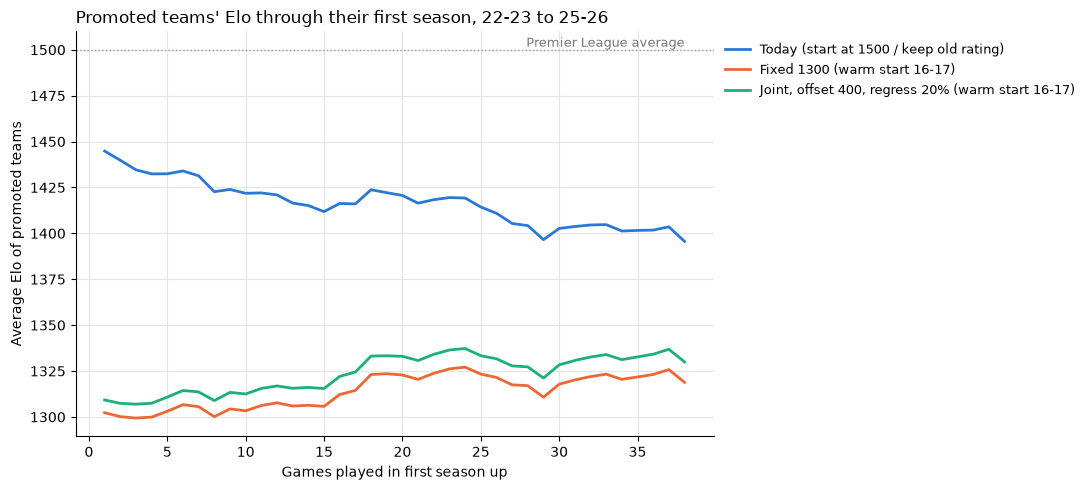

In [9]:
best_fixed = significance[significance["Elo variant"].str.startswith("Fixed")].iloc[0]
best_joint = significance[significance["Elo variant"].str.startswith("Joint")].iloc[0]

plot_variants = {
    "Today (start at 1500 / keep old rating)": (variants[baseline_key], "#2a78d6"),
    f"{best_fixed['Elo variant']} ({best_fixed['History']})": (variants[(best_fixed["Elo variant"], best_fixed["History"])], "#eb6834"),
    f"{best_joint['Elo variant']} ({best_joint['History']})": (variants[(best_joint["Elo variant"], best_joint["History"])], "#1baf7a"),
}

track = {key for key in promoted_set if key[0] in test_seasons}

fig, ax = plt.subplots(figsize=(11, 5))
for label, (settings, color) in plot_variants.items():
    _, history = run_elo(**settings, track=track)
    history["Game"] = history.groupby(["Season", "Team"]).cumcount() + 1
    curve = history.groupby("Game")["Rating"].mean()
    ax.plot(curve.index, curve.values, color=color, linewidth=2, label=label)

ax.axhline(1500, color="#999", linestyle=":", linewidth=1)
ax.text(38, 1500, "Premier League average", color="#777", va="bottom", ha="right", fontsize=9)
ax.set_xlabel("Games played in first season up")
ax.set_ylabel("Average Elo of promoted teams")
ax.set_title("Promoted teams' Elo through their first season, 22-23 to 25-26", loc="left")
ax.grid(color="#e5e5e5", linewidth=0.8)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## Bonus: the stale xG history

`XGDDiffLast5` has the same problem: a promoted team's "last 5" are either
nothing (counted as 0 = average) or its final games from a previous
Premier League stint. Here a promoted team's window only counts games from
its current stint, and any missing slots are filled with a prior xG
difference `prior` (0 = average, negative = below average). Tested on top
of today's Elo and the best joint Elo.

In [10]:
def xgd_last5_fresh(prior):
    """XGDDiffLast5, but a promoted team's history restarts on promotion,
    with empty slots filled by ``prior``."""

    history = {}
    values = []

    for row in epl.itertuples():
        diffs = []
        for team in (row.HomeTeam, row.AwayTeam):
            if (row.Season, team) in promoted_set and history.get(team, ("", []))[0] != row.Season:
                history[team] = (row.Season, [])  # fresh start this season
            last5 = history.setdefault(team, (row.Season, []))[1][-5:]
            if (row.Season, team) in promoted_set:
                xgd = (sum(last5) + prior * (5 - len(last5))) / 5
            else:
                xgd = np.mean(last5) if last5 else 0.0
            diffs.append(xgd)
        values.append(diffs[0] - diffs[1])

        if pd.notna(row.HomeXG) and pd.notna(row.AwayXG):
            history[row.HomeTeam][1].append(row.HomeXG - row.AwayXG)
            history[row.AwayTeam][1].append(row.AwayXG - row.HomeXG)

    return np.array(values)

best_joint_key = (best_joint["Elo variant"], best_joint["History"])
xgd_rows = []
for prior in [0.0, -0.3, -0.6, -0.9]:
    fresh = xgd_last5_fresh(prior)
    for elo_key in [baseline_key, best_joint_key]:
        proba = walk_forward(elo_variants[elo_key], xgd=fresh)
        probas[(f"{elo_key[0]} + fresh xG prior {prior}", elo_key[1])] = proba
        xgd_rows.append({
            "Elo": f"{elo_key[0]} ({elo_key[1]})",
            "xG prior": prior,
            **score(proba),
            **{k: v for k, v in versus_baseline(proba).items() if k in ("Diff (all)", "P(better, all)", "Diff (promoted)")},
        })

pd.DataFrame(xgd_rows).sort_values("LogLoss").reset_index(drop=True)

,Elo,xG prior,LogLoss,Accuracy,Promoted LogLoss,Promoted first-10 LogLoss,Promoted accuracy,Diff (all),"P(better, all)",Diff (promoted)
0,Carry (today) (from 21-22),-0.9,0.9807,0.5441,0.9061,0.8947,0.5949,0.0002,0.3422,0.0011
1,Carry (today) (from 21-22),-0.6,0.9808,0.5434,0.9065,0.8968,0.5949,0.0003,0.2296,0.0015
2,Carry (today) (from 21-22),-0.3,0.9810,0.5441,0.9069,0.8991,0.5972,0.0005,0.1422,0.0020
3,Carry (today) (from 21-22),0.0,0.9811,0.5454,0.9074,0.9018,0.5972,0.0007,0.1038,0.0025
4,"Joint, offset 400, regress 20% (warm start 16-17)",-0.9,0.9821,0.5474,0.9141,0.9087,0.5903,0.0017,0.2862,0.0092
5,"Joint, offset 400, regress 20% (warm start 16-17)",-0.6,0.9822,0.5474,0.9143,0.9091,0.5903,0.0017,0.2812,0.0094
6,"Joint, offset 400, regress 20% (warm start 16-17)",-0.3,0.9822,0.5461,0.9145,0.9096,0.5903,0.0018,0.2740,0.0096
7,"Joint, offset 400, regress 20% (warm start 16-17)",0.0,0.9823,0.5461,0.9148,0.9104,0.5903,0.0019,0.2672,0.0098


## Conclusion

**Promoted teams really are rated too high today.** They averaged 0.82
points per game in their first season up (an average side gets ~1.37), yet
today's Elo starts them at ~1445 on average and they're still ~1400 after
38 games. A fixed start of 1300 settles them around 1310-1330, which is
where their results say they belong.

**A lower fixed starting rating is the only change that helps - and only
slightly.**

| Elo variant | All matches | Promoted matches | Promoted, first 10 games |
|---|---|---|---|
| Today (carry) | 0.9805 | 0.9049 | 0.8932 |
| Fixed 1350 (from 21-22) | 0.9800 | 0.9051 | 0.8845 |
| Fixed 1300 (warm start 16-17) | 0.9796 | 0.9051 | 0.8837 |
| Inherit relegated | 0.9805 | 0.9067 | 0.8966 |
| Joint with Championship (best: offset 400) | 0.9819 | 0.9130 | 0.9041 |

The gain is concentrated where you'd expect - a promoted team's first ten
games (about 1% better log loss) - and fades as `GoalsPerGameDiff` and
`XGDDiffLast5` catch up with reality. Over all matches it's within noise
(95% CI -0.005 to +0.004), and when the starting rating is chosen on
22-23/23-24 and tested on 24-25/25-26 it comes out level with today.

**The Championship doesn't help - it makes things slightly worse.** Every
joint Elo setting is worse than today's model. On average the joint
ratings start promoted teams in the same place as a fixed 1300-1350 (see
the chart), so the only thing the Championship adds is *which* promoted
team looks stronger, and that turns out to be noise: Championship
dominance doesn't carry over. Burnley won the 22-23 Championship with 101
points and took 0.63 PPG the next season; Sunderland came up through the
play-offs and took 1.42.

**Smaller findings**

- Warm-starting Elo from 16-17 doesn't help on its own (0.9818) - with
  K = 35 the ratings forget old seasons quickly anyway, and it makes
  returning teams' carried ratings even staler.
- Inheriting the relegated teams' ratings is neutral.
- Restarting a promoted team's `XGDDiffLast5` history (with any prior from
  0 to -0.9) doesn't help.

**Recommendation (now implemented as `PROMOTED_ELO` in
`predict_next_matches.py`):** don't add the Championship to the pipeline. Instead,
start every promoted team (new or returning) at a fixed **1350** in
`build_elo_feature` and when scoring future fixtures - a small,
principled fix with no extra data, that doesn't hurt anywhere and helps
early-season predictions a little. In a multi-league version (notebook
18) the same rule would apply per league.